In [8]:
import sqlite3
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Load data
conn = sqlite3.connect('../data/energy_data.db')
df = pd.read_sql_query("SELECT * FROM energy_master", conn)
conn.close()

df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)
df = df.set_index('timestamp')

# Feature Engineering: Time and Weather variables
df['hour'] = df.index.hour
df['day_of_week'] = df.index.day_of_week
df['month'] = df.index.month

# Define features (X) and target (y)
features = ['wind', 'solar', 'hour', 'day_of_week', 'month']
model_data = df[features + ['price_eur_mwh']].dropna()

X = model_data[features]
y = model_data['price_eur_mwh']

In [9]:
# Chronological split (80% train, 20% test) to prevent time-series data leakage
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Train Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Generate predictions
y_pred = rf_model.predict(X_test)

Mean Absolute Error (MAE): 40.39 €/MWh
Root Mean Squared Error (RMSE): 51.76 €/MWh
Weighted Absolute Percentage Error (WAPE): 23.69%
R-squared (R²): 0.650


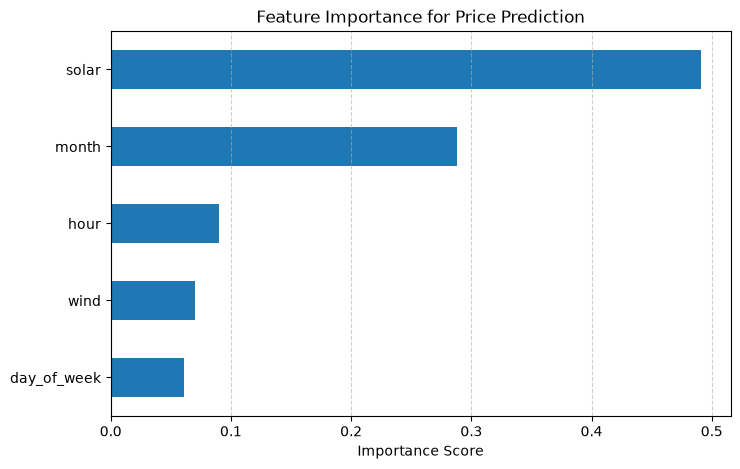

In [11]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Calculate error metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

# Calculate WAPE to avoid division by zero (common in energy markets)
wape = (np.sum(np.abs(y_test - y_pred)) / np.sum(y_test)) * 100

print(f"Mean Absolute Error (MAE): {mae:.2f} €/MWh")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} €/MWh")
print(f"Weighted Absolute Percentage Error (WAPE): {wape:.2f}%")
print(f"R-squared (R²): {r2:.3f}")

# Plot Feature Importance
importance = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)
plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='tab:blue')
plt.title('Feature Importance for Price Prediction')
plt.xlabel('Importance Score')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

### Predictive Modeling: Random Forest Regressor
* **Model Performance:** The model explains 65% of the price variance (R²: 0.650) with an average error (MAE) of 40.39 €/MWh. A higher RMSE (51.76 €/MWh) indicates the model occasionally struggles with extreme price spikes. We use WAPE (Weighted Absolute Percentage Error), which stands at **23.69%**, instead of MAPE to robustly evaluate error in a market that frequently features 0 €/MWh prices, avoiding division-by-zero artifacts.
* **Key Drivers:** The feature importance chart clearly shows that **solar generation** is the dominant factor in predicting electricity prices. Seasonality (**month**) is the second most critical driver, followed by daily demand cycles (**hour**). Wind generation and the day of the week have the lowest impact on the model's predictions.